# AetherForge – Predictive Asset Failure Intelligence System

### Phase 1: Data Understanding & Exploratory Data Analysis (EDA)

**Dataset:** NASA CMAPSS FD001 (Turbofan Engine Degradation)

In [43]:
# Basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Display settings
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")


In [44]:
import os


downloads_path = r"C:\Users\HP\Downloads"

print("Downloads folder ke andar yeh cheezein hain:\n")
for item in os.listdir(downloads_path):
    print(item)

Downloads folder ke andar yeh cheezein hain:

01_Infrastructure_Assets.csv
02_IT_Services.csv
03_SLA_Definitions.csv
04ee55cd-73bc-4457-be33-1d4f1f523401.png
04_Performance_Metrics.csv
05_Incidents.csv
06_Business_Impact.csv
07_Changes.csv
08_Security_Events.csv
09_Patch_Compliance.csv
123.jpg
12345.pbix
1612365605_chhatrapati-shivaji-jayanti-images-with-name.webp
197300330_ExamForm.PDF
197300330_PreviewExamForm.PDF
1e544a99-793e-4503-b91d-41564c3b539a.png
20201216-liam-squat-camp-sm.jpg
2025_AnnualReport.docx
2baa7f94-717f-469c-95ec-d1bf455aae12.png
31099743711-JUL-25223244 (1).PDF
31099743711-JUL-25223244.PDF
36c3c8a4-020d-43f6-8528-8d17c92576bd.png
5822259-2920x1640-desktop-hd-cute-laptop-background-image.jpg
5e632cde-d84f-4034-9e1c-5b5055a08a9c.png
665614902_12TH MARKSHEET (1).jpg
665614902_12TH MARKSHEET.jpg
709551058_10TH MARKSHEET.jpg
aaaaaa.pbix
abcf.pbix
ADDITION ACT.zip
AdventureWorks.sql
AdventureWorksDW.XLSX
AdventureWorks_SQL_Project.sql
AetherForge (1).ipynb
AetherForge.i

In [45]:
import os


path1 = r"C:\Users\HP\Downloads\NASA-CMAPSS-dataset-main"
path2 = r"C:\Users\HP\Downloads\NASA-CMAPSS-dataset-main\NASA-CMAPSS-dataset-main"

print("Path 1", os.path.exists(path1))
print("Path 2", os.path.exists(path2))

print("\n--- Path 1 ---")
if os.path.exists(path1):
    print(os.listdir(path1))

print("\n--- Path 2 ---")
if os.path.exists(path2):
    print(os.listdir(path2))


Path 1 True
Path 2 False

--- Path 1 ---
['Damage Propagation Modeling.pdf', 'LICENSE', 'README.md', 'readme.txt', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']

--- Path 2 ---


In [46]:
import os
import pandas as pd


# 1. Set your path here

DATA_DIR = r"C:\Users\HP\Downloads\NASA-CMAPSS-dataset-main"

# 2. Check if folder exists

print("Checking path...")
print("Exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("\nFiles inside folder:")
    print(os.listdir(DATA_DIR))
else:
    print("\nFolder not found. Please extract the ZIP file first.")

Checking path...
Exists: True

Files inside folder:
['Damage Propagation Modeling.pdf', 'LICENSE', 'README.md', 'readme.txt', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


In [47]:
import os

DATA_DIR = r"C:\Users\HP\Downloads\NASA-CMAPSS-dataset-main"

print("Exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print(os.listdir(DATA_DIR))
else:
    print("Still not found. ZIP is not extracted.")

Exists: True
['Damage Propagation Modeling.pdf', 'LICENSE', 'README.md', 'readme.txt', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


In [48]:
import zipfile
import os

zip_path = r"C:\Users\HP\Downloads\NASA-CMAPSS-dataset-main.zip"
extract_to = r"C:\Users\HP\Downloads"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print("Extraction completed successfully!")
else:
    print("ZIP file not found.")

ZIP exists: True
Extraction completed successfully!


In [49]:
import os

DATA_DIR = r"C:\Users\HP\Downloads\NASA-CMAPSS-dataset-main"

print("Exists:", os.path.exists(DATA_DIR))
if os.path.exists(DATA_DIR):
    print(os.listdir(DATA_DIR))

Exists: True
['Damage Propagation Modeling.pdf', 'LICENSE', 'README.md', 'readme.txt', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


In [50]:
column_names = [
    'unit', 'cycle',
    'setting_1', 'setting_2', 'setting_3',
    'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5',
    'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10',
    'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15',
    'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20',
    'sensor_21'
]

DATA_DIR = r"C:\Users\HP\Downloads\NASA-CMAPSS-dataset-main"

train = pd.read_csv(f"{DATA_DIR}/train_FD001.txt", sep=r'\s+', header=None, names=column_names)
test  = pd.read_csv(f"{DATA_DIR}/test_FD001.txt",  sep=r'\s+', header=None, names=column_names)
rul   = pd.read_csv(f"{DATA_DIR}/RUL_FD001.txt",   sep=r'\s+', header=None, names=['RUL'])

print("Data loaded successfully!")
print(f"Train shape : {train.shape}")
print(f"Test shape  : {test.shape}")
print(f"RUL shape   : {rul.shape}")

Data loaded successfully!
Train shape : (20631, 26)
Test shape  : (13096, 26)
RUL shape   : (100, 1)


In [51]:
print("Training Data - First 5 rows:")
print(train.head())

print("\nTrain Info:")
print(f"Number of engines : {train['unit'].nunique()}")
print(f"Total rows        : {len(train)}")

Training Data - First 5 rows:
   unit  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  \
0     1      1    -0.0007    -0.0004      100.0    518.67    641.82   1589.70   1400.60     14.62     21.61    554.36   
1     1      2     0.0019    -0.0003      100.0    518.67    642.15   1591.82   1403.14     14.62     21.61    553.75   
2     1      3    -0.0043     0.0003      100.0    518.67    642.35   1587.99   1404.20     14.62     21.61    554.26   
3     1      4     0.0007     0.0000      100.0    518.67    642.35   1582.79   1401.87     14.62     21.61    554.45   
4     1      5    -0.0019    -0.0002      100.0    518.67    642.37   1582.85   1406.22     14.62     21.61    554.00   

   sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  \
0   2388.06   9046.19        1.3      47.47     521.66    2388.02    8138.62     8.4195       0.03        392   
1   2388.04   904

In [52]:
# Calculate RUL
max_cycle = train.groupby('unit')['cycle'].max().reset_index()
max_cycle.columns = ['unit', 'max_cycle']

train = train.merge(max_cycle, on='unit', how='left')
train['RUL'] = train['max_cycle'] - train['cycle']
train = train.drop(columns=['max_cycle'])

print("RUL column added!")
print("\nEngine 1 - Last 8 cycles:")
print(train[train['unit'] == 1][['unit', 'cycle', 'RUL']].tail(8))

RUL column added!

Engine 1 - Last 8 cycles:
     unit  cycle  RUL
184     1    185    7
185     1    186    6
186     1    187    5
187     1    188    4
188     1    189    3
189     1    190    2
190     1    191    1
191     1    192    0


In [53]:
cycles_per_engine = train.groupby('unit')['cycle'].max()

print("Training Engines - Life Statistics:")
print(f"  Minimum life : {cycles_per_engine.min()} cycles")
print(f"  Maximum life : {cycles_per_engine.max()} cycles")
print(f"  Average life : {cycles_per_engine.mean():.1f} cycles")
print(f"  Median life  : {cycles_per_engine.median():.1f} cycles")

print("\nTest Set - True RUL Statistics:")
print(f"  Min RUL  : {rul['RUL'].min()}")
print(f"  Max RUL  : {rul['RUL'].max()}")
print(f"  Mean RUL : {rul['RUL'].mean():.1f}")

Training Engines - Life Statistics:
  Minimum life : 128 cycles
  Maximum life : 362 cycles
  Average life : 206.3 cycles
  Median life  : 199.0 cycles

Test Set - True RUL Statistics:
  Min RUL  : 7
  Max RUL  : 145
  Mean RUL : 75.5


In [54]:
sensor_cols = [col for col in train.columns if col.startswith('sensor_')]

stds = train[sensor_cols].std()
constant_sensors = stds[stds < 0.001].index.tolist()

print("Constant sensors (can be dropped):")
print(constant_sensors)

print("\nUseful sensors:")
useful_sensors = [s for s in sensor_cols if s not in constant_sensors]
print(useful_sensors)

Constant sensors (can be dropped):
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Useful sensors:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


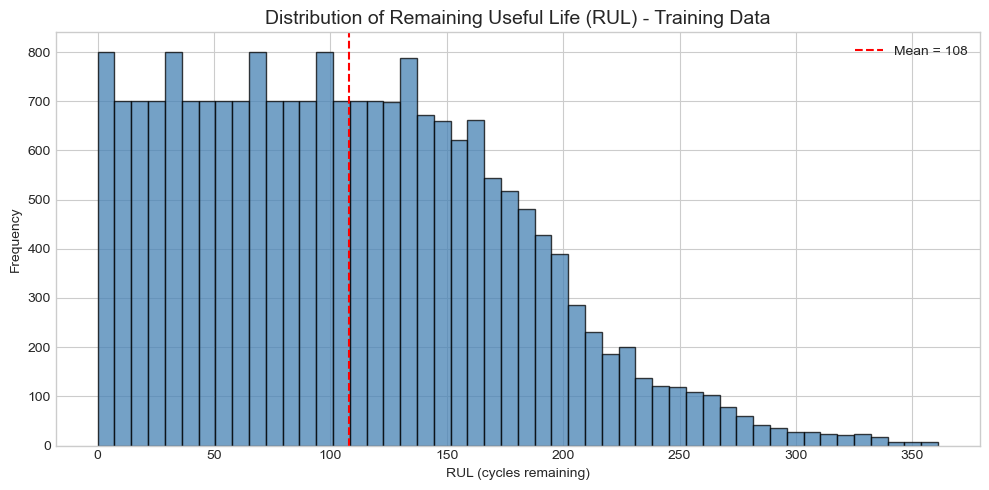

In [55]:
plt.figure(figsize=(10, 5))
plt.hist(train['RUL'], bins=50, color='steelblue', edgecolor='black', alpha=0.75)
plt.title('Distribution of Remaining Useful Life (RUL) - Training Data', fontsize=14)
plt.xlabel('RUL (cycles remaining)')
plt.ylabel('Frequency')
plt.axvline(train['RUL'].mean(), color='red', linestyle='--', label=f'Mean = {train["RUL"].mean():.0f}')
plt.legend()
plt.tight_layout()
plt.show()

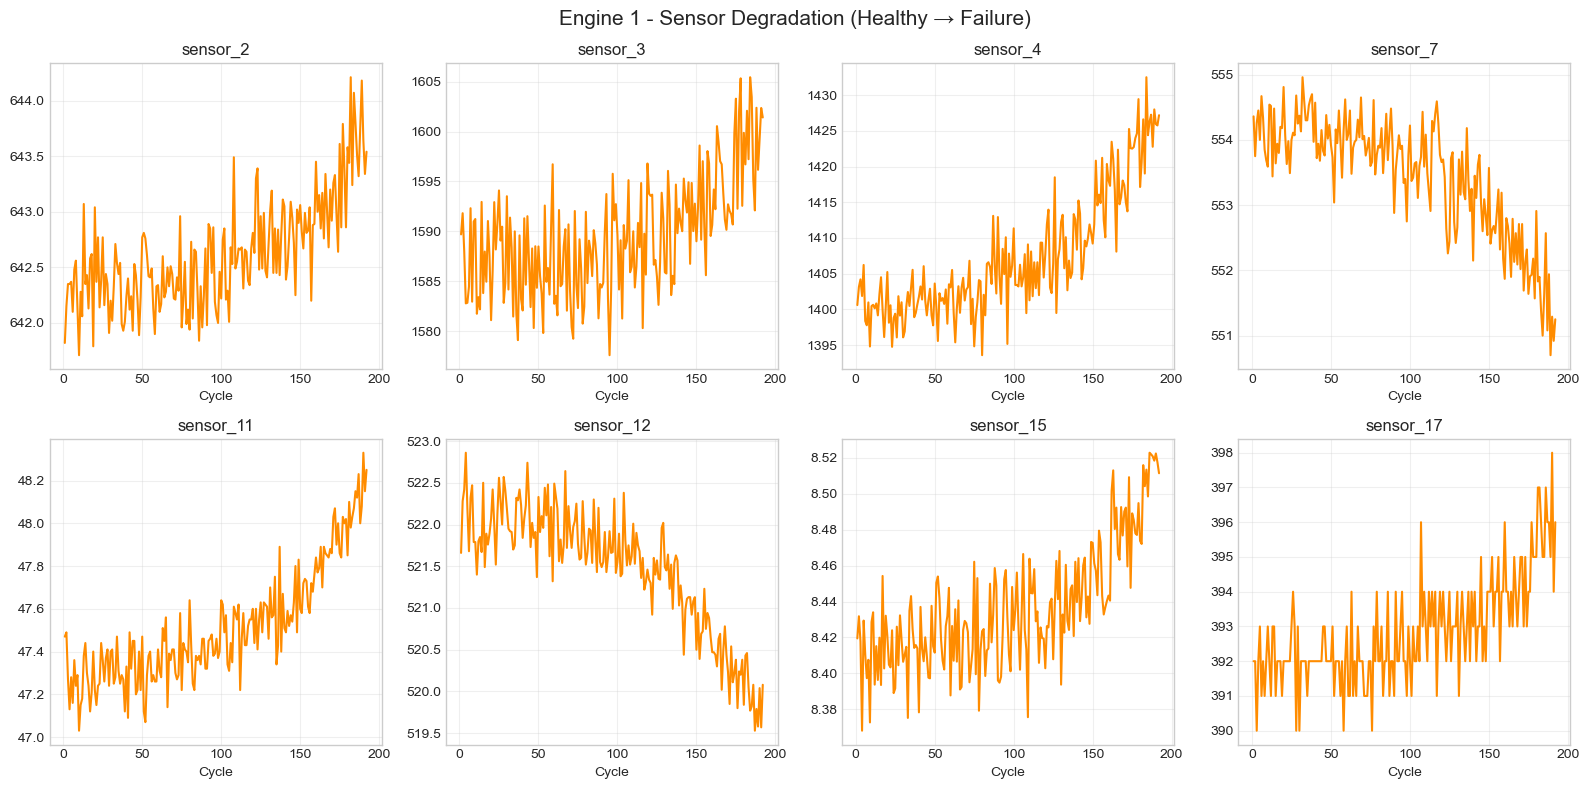

In [56]:
important_sensors = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7',
                     'sensor_11', 'sensor_12', 'sensor_15', 'sensor_17']

engine1 = train[train['unit'] == 1]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, sensor in enumerate(important_sensors):
    axes[i].plot(engine1['cycle'], engine1[sensor], color='darkorange', linewidth=1.5)
    axes[i].set_title(sensor)
    axes[i].set_xlabel('Cycle')
    axes[i].grid(True, alpha=0.3)

fig.suptitle('Engine 1 - Sensor Degradation (Healthy → Failure)', fontsize=15)
plt.tight_layout()
plt.show()

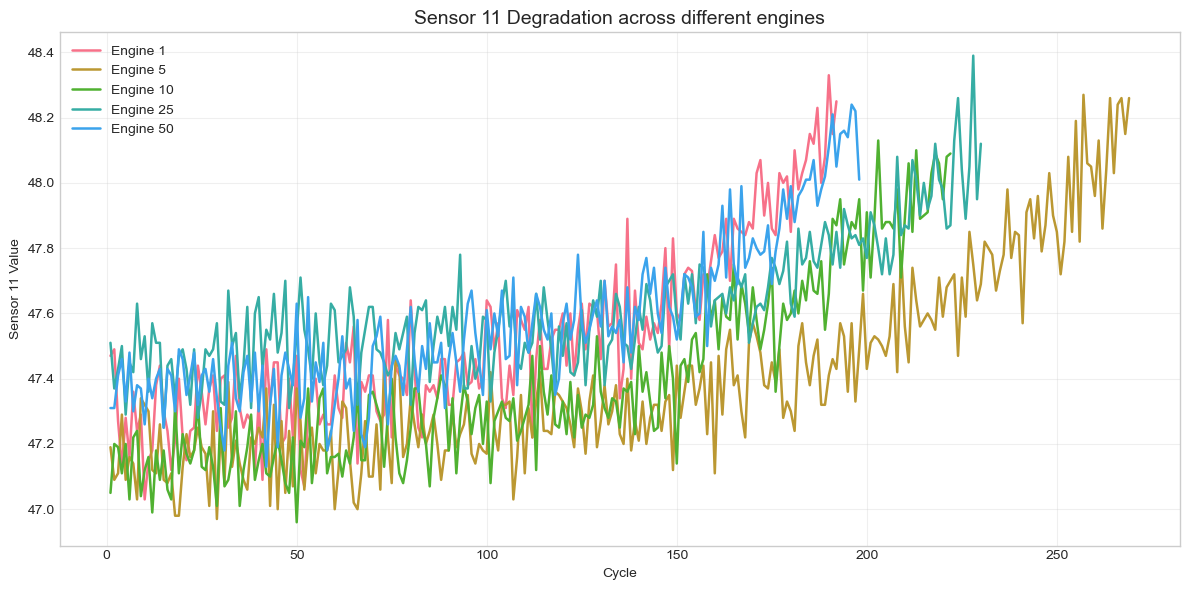

In [57]:
plt.figure(figsize=(12, 6))

for unit in [1, 5, 10, 25, 50]:
    eng = train[train['unit'] == unit]
    plt.plot(eng['cycle'], eng['sensor_11'], label=f'Engine {unit}', linewidth=1.8)

plt.title('Sensor 11 Degradation across different engines', fontsize=14)
plt.xlabel('Cycle')
plt.ylabel('Sensor 11 Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
rul_corr = train[useful_sensors + ["RUL"]].corr()["RUL"].sort_values()

print(rul_corr)

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
RUL          1.000000
Name: RUL, dtype: float64


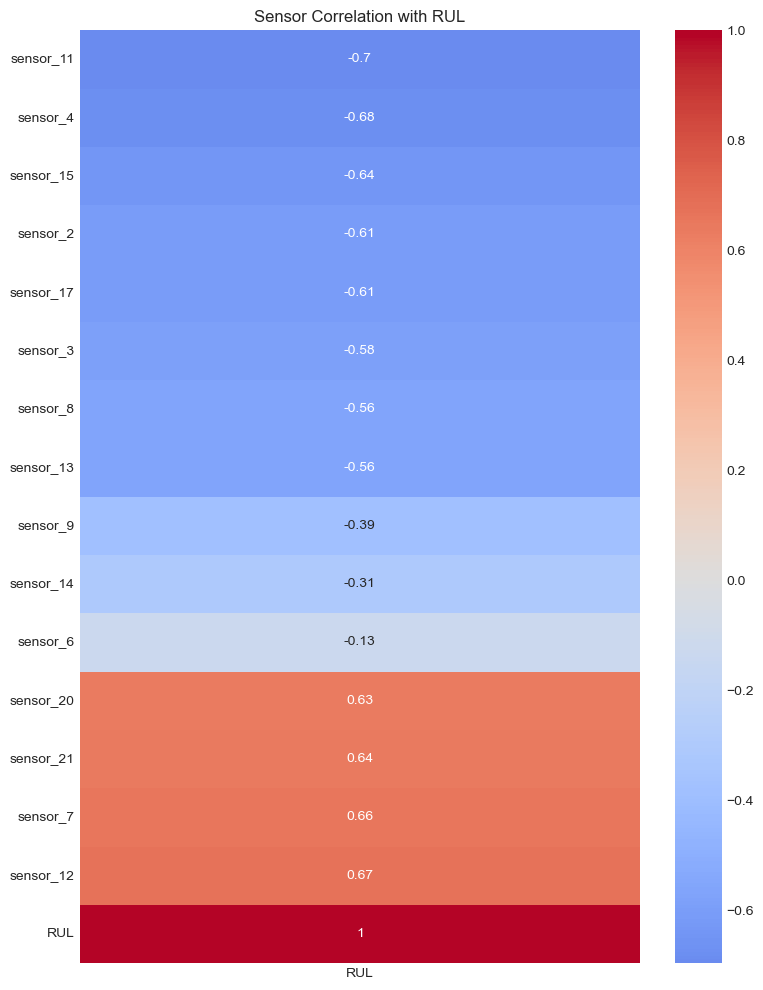

In [59]:
plt.figure(figsize=(8, 10))

sns.heatmap(
    rul_corr.to_frame(),
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Sensor Correlation with RUL")
plt.tight_layout()
plt.show()

I calculated the correlation between sensor measurements and Remaining Useful Life. Sensors such as sensor_11, sensor_4, and sensor_15 showed strong negative correlation with RUL, while sensor_12, sensor_7, and sensor_21 showed strong positive correlation. These sensors were therefore identified as important candidates for further feature engineering and predictive modeling.

In [60]:
# Drop constant sensors
constant_sensors = ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

# Features we will use
feature_cols = ['setting_1', 'setting_2', 'setting_3'] + [s for s in sensor_cols if s not in constant_sensors]

print("Selected features:")
print(feature_cols)
print(f"\nTotal features: {len(feature_cols)}")

Selected features:
['setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Total features: 18


In [61]:
# Create scaler
scaler = MinMaxScaler()

# Fit on training data only
train[feature_cols] = scaler.fit_transform(train[feature_cols])

# Transform test data with same scaler
test[feature_cols] = scaler.transform(test[feature_cols])

print("Normalization done!")
print("\nTrain data sample after scaling:")
print(train[feature_cols].head(3))

Normalization done!

Train data sample after scaling:
   setting_1  setting_2  setting_3  sensor_2  sensor_3  sensor_4  sensor_6  sensor_7  sensor_8  sensor_9  sensor_11  \
0   0.459770   0.166667        0.0  0.183735  0.406802  0.309757       1.0  0.726248  0.242424  0.109755   0.369048   
1   0.609195   0.250000        0.0  0.283133  0.453019  0.352633       1.0  0.628019  0.212121  0.100242   0.380952   
2   0.252874   0.750000        0.0  0.343373  0.369523  0.370527       1.0  0.710145  0.272727  0.140043   0.250000   

   sensor_12  sensor_13  sensor_14  sensor_15  sensor_17  sensor_20  sensor_21  
0   0.633262   0.205882   0.199608   0.363986   0.333333   0.713178   0.724662  
1   0.765458   0.279412   0.162813   0.411312   0.333333   0.666667   0.731014  
2   0.795309   0.220588   0.171793   0.357445   0.166667   0.627907   0.621375  


In [62]:

def create_sequences(data, feature_cols, sequence_length=30):
    sequences = []
    labels = []
    
    for unit in data['unit'].unique():
        unit_data = data[data['unit'] == unit]
        
        for i in range(len(unit_data) - sequence_length + 1):
            seq = unit_data[feature_cols].iloc[i : i + sequence_length].values
            label = unit_data['RUL'].iloc[i + sequence_length - 1]
            sequences.append(seq)
            labels.append(label)
            
    return np.array(sequences), np.array(labels)

# Create sequences for training data
sequence_length = 30
X_train, y_train = create_sequences(train, feature_cols, sequence_length)

print("Sequences created!")
print(f"X_train shape : {X_train.shape}")  # (samples, timesteps, features)
print(f"y_train shape : {y_train.shape}")

Sequences created!
X_train shape : (17731, 30, 18)
y_train shape : (17731,)


In [63]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, y_train, 
    test_size=0.2, 
    random_state=42
)

print("Train-Validation split done!")
print(f"X_train_final : {X_train_final.shape}")
print(f"X_val         : {X_val.shape}")
print(f"y_train_final : {y_train_final.shape}")
print(f"y_val         : {y_val.shape}")

Train-Validation split done!
X_train_final : (14184, 30, 18)
X_val         : (3547, 30, 18)
y_train_final : (14184,)
y_val         : (3547,)


 Insights

- **Constant sensors removed**: sensor_1, 5, 10, 16, 18, 19 (no useful variation)
- **Features selected**: 18 (settings + useful sensors)
- **Normalization**: MinMaxScaler (0 to 1) applied to avoid scale issues
- **Sequences created**: Window size = 30 → Shape (samples, 30, 18)
- **Split**: 80% Train | 20% Validation

**Final Shapes:**
- X_train: (14184, 30, 18)
- X_val: (3547, 30, 18)

In [64]:
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(30, 18)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model.summary()

C:\Users\HP\Anaconda2025\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,209 (133.63 KB)

 Trainable params: 34,209 (133.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - loss: 9187.3428 - mae: 75.9805 - val_loss: 5864.3218 - val_mae: 58.5987
Epoch 2/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - loss: 4515.3770 - mae: 52.8866 - val_loss: 3849.4324 - val_mae: 50.2160
Epoch 3/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 3919.1255 - mae: 50.8117 - val_loss: 3825.8623 - val_mae: 50.4357
Epoch 4/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 3897.7529 - mae: 50.8296 - val_loss: 3826.5623 - val_mae: 50.5633
Epoch 5/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 3891.1619 - mae: 50.7625 - val_loss: 3823.3621 - val_mae: 50.4136
Epoch 6/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 3331.4243 - mae: 45.3373 - val_loss: 2168.3477 - val_mae: 33.9738
Epoch 7/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - loss: 1770.4244 - mae: 30.2735 - val_loss: 1449.6144 - val_mae: 27.9979
Epoch 8/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - loss: 1330.9161 - mae: 25.3979 - val_loss: 1185.3608 

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title('Mean Absolute Error')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Predictions on validation set
y_pred = model.predict(X_val).flatten()

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print(f"Validation MAE  : {mae:.2f}")
print(f"Validation RMSE : {rmse:.2f}")

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_val, y_pred, alpha=0.4, color='steelblue')
plt.plot([0, 150], [0, 150], 'r--', label='Perfect Prediction')
plt.xlabel('True RUL')
plt.ylabel('Predicted RUL')
plt.title('Actual vs Predicted RUL (Validation Set)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Create sequences for test data (last window of each engine)
def create_test_sequences(data, feature_cols, sequence_length=30):
    sequences = []
    for unit in data['unit'].unique():
        unit_data = data[data['unit'] == unit]
        if len(unit_data) >= sequence_length:
            seq = unit_data[feature_cols].iloc[-sequence_length:].values
            sequences.append(seq)
        else:
            # pad if needed (rare)
            pad_len = sequence_length - len(unit_data)
            pad = np.zeros((pad_len, len(feature_cols)))
            seq = np.vstack([pad, unit_data[feature_cols].values])
            sequences.append(seq)
    return np.array(sequences)

X_test = create_test_sequences(test, feature_cols, sequence_length=30)
y_test_true = rul['RUL'].values

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test_true.shape)

# Predict
y_test_pred = model.predict(X_test).flatten()

# Metrics
mae_test = mean_absolute_error(y_test_true, y_test_pred)
rmse_test = np.sqrt(mean_squared_error(y_test_true, y_test_pred))

print(f"\nTest MAE  : {mae_test:.2f}")
print(f"Test RMSE : {rmse_test:.2f}")

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_true, y_test_pred, alpha=0.7, color='teal')
plt.plot([0, 150], [0, 150], 'r--', label='Perfect Prediction')
plt.xlabel('True RUL')
plt.ylabel('Predicted RUL')
plt.title('Actual vs Predicted RUL (Test Set)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Phase 3: Deep Learning Model - Detailed Insights

### Model Architecture
- **2-layer LSTM** (64 units → 32 units)
- Dropout (0.2) after each LSTM to reduce overfitting
- Dense layers for final RUL prediction
- Loss: MSE | Metric: MAE | Optimizer: Adam

### Why LSTM?
- Sensor data is sequential (time-series)
- LSTM can remember long-term patterns of degradation
- Suitable for Remaining Useful Life prediction

### Training Behavior
- Loss and MAE dropped sharply after epoch 10
- Validation and training curves are close → low overfitting
- EarlyStopping was ready but model improved till the end

### Results Interpretation
| Set        | MAE    | RMSE   | Meaning                                      |
|------------|--------|--------|----------------------------------------------|
| Validation | 19.27  | 28.39  | Average error ~19 cycles on unseen train data |
| **Test**   | **16.67** | **24.45** | Average error ~17 cycles on real test engines |


In [ ]:
# Sample technical documents for RAG
documents = [
    {
        "id": "doc1",
        "title": "HPC Degradation - Common Failure Mode",
        "content": "High Pressure Compressor (HPC) degradation is one of the most common failure modes in turbofan engines. Symptoms include gradual increase in exhaust gas temperature, decrease in core speed, and rising vibration levels. Recommended action: Schedule borescope inspection of HPC blades and check for blade tip clearance."
    },
    {
        "id": "doc2",
        "title": "Fan Degradation Symptoms",
        "content": "Fan degradation typically shows increasing vibration in the low-pressure shaft and reduced fan efficiency. Sensors related to fan speed and low-pressure turbine temperature often show abnormal trends. Recommended action: Inspect fan blades for foreign object damage and check fan balance."
    },
    {
        "id": "doc3",
        "title": "Vibration Increase Near Failure",
        "content": "A steady rise in vibration sensors (especially sensor related to bearing and shaft) in the last 30-50 cycles is a strong indicator of impending mechanical failure. Immediate action: Reduce operating load and plan for maintenance within 10-15 cycles."
    },
    {
        "id": "doc4",
        "title": "Temperature Rise Pattern",
        "content": "Progressive increase in temperature sensors (EGT or turbine temperature) combined with pressure drop indicates efficiency loss due to blade wear or seal leakage. Recommended action: Perform performance trend analysis and schedule hot section inspection."
    },
    {
        "id": "doc5",
        "title": "Remaining Useful Life Guidelines",
        "content": "When predicted RUL falls below 30 cycles, the engine should be prioritized for maintenance. If RUL is below 15 cycles, immediate grounding or limited operation is recommended until inspection is completed."
    },
    {
        "id": "doc6",
        "title": "Sensor 11 and Sensor 4 Interpretation",
        "content": "Sensor 11 (static pressure) and Sensor 4 (temperature related) showing strong negative correlation with RUL means that as these values increase, remaining life decreases. These two sensors are among the most reliable early indicators of degradation."
    }
]

print(f"Knowledge base created with {len(documents)} documents.")
for doc in documents:
    print(f"- {doc['id']}: {doc['title']}")

In [ ]:
corpus = [doc['content'] for doc in documents]
doc_ids = [doc['id'] for doc in documents]
doc_titles = [doc['title'] for doc in documents]

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(corpus)

def retrieve_documents(query, top_k=3):
    query_vec = vectorizer.transform([query])
    scores = cosine_similarity(query_vec, tfidf_matrix).flatten()
    top_indices = scores.argsort()[-top_k:][::-1]
    
    results = []
    for idx in top_indices:
        results.append({
            "id": doc_ids[idx],
            "title": doc_titles[idx],
            "content": corpus[idx],
            "score": round(float(scores[idx]), 3)
        })
    return results

# Test
query = "engine vibration increasing and high temperature"
results = retrieve_documents(query)

print("Query:", query)
print("\nTop retrieved documents:")
for r in results:
    print(f"\n[{r['id']}] {r['title']} (score: {r['score']})")
    print(r['content'][:180], "...")

In [ ]:
def generate_intelligence_report(predicted_rul, top_sensors_info="vibration and temperature rising"):
    
    # Create query from prediction
    if predicted_rul < 15:
        urgency = "CRITICAL"
        query = f"engine failure imminent low RUL {top_sensors_info}"
    elif predicted_rul < 30:
        urgency = "HIGH"
        query = f"engine degradation {top_sensors_info} maintenance required"
    else:
        urgency = "MEDIUM"
        query = f"engine health monitoring {top_sensors_info}"
    
    # Retrieve relevant documents
    retrieved = retrieve_documents(query, top_k=3)
    
    # Build report
    print("=" * 60)
    print("AETHERFORGE - PREDICTIVE INTELLIGENCE REPORT")
    print("=" * 60)
    print(f"\nPredicted RUL       : {predicted_rul:.1f} cycles")
    print(f"Risk Level          : {urgency}")
    print(f"\nKey Observation     : {top_sensors_info}")
    
    print("\n" + "-" * 60)
    print("RETRIEVED TECHNICAL KNOWLEDGE:")
    print("-" * 60)
    
    for i, doc in enumerate(retrieved, 1):
        print(f"\n{i}. [{doc['id']}] {doc['title']}")
        print(f"   Relevance Score: {doc['score']}")
        print(f"   {doc['content']}")
    
    print("\n" + "-" * 60)
    print("RECOMMENDED ACTIONS:")
    print("-" * 60)
    
    if predicted_rul < 15:
        print("→ Immediate inspection required")
        print("→ Limit engine operation")
        print("→ Schedule maintenance within 5-10 cycles")
    elif predicted_rul < 30:
        print("→ Plan maintenance within next 15-20 cycles")
        print("→ Increase monitoring frequency")
        print("→ Perform borescope inspection")
    else:
        print("→ Continue normal operation")
        print("→ Keep monitoring sensor trends")
    
    print("=" * 60)

# Example: Test with a low RUL prediction
generate_intelligence_report(predicted_rul=12.5, top_sensors_info="vibration increasing and temperature rising")

## Phase 4: RAG + Intelligence Report

- Created a domain knowledge base (6 technical documents)
- Used TF-IDF based retrieval to find relevant documents
- Connected predicted RUL with retrieved knowledge
- Generated complete intelligence report with:
  - Risk Level
  - Supporting technical documents
  - Recommended actions

This closes the gap between prediction and actionable maintenance intelligence.

In [ ]:
def aetherforge_predict(engine_unit, test_data, model, feature_cols, sequence_length=30):
    """
    Complete AetherForge Pipeline
    """
    
    # 1. Get engine data
    engine_data = test_data[test_data['unit'] == engine_unit]
    
    if len(engine_data) < sequence_length:
        print(f"Engine {engine_unit} has insufficient data")
        return
    
    # 2. Create sequence (last 30 cycles)
    seq = engine_data[feature_cols].iloc[-sequence_length:].values
    seq = np.expand_dims(seq, axis=0)  # shape (1, 30, 18)
    
    # 3. Predict RUL
    predicted_rul = model.predict(seq, verbose=0).flatten()[0]
    
    # 4. Generate Intelligence Report
    generate_intelligence_report(
        predicted_rul=predicted_rul,
        top_sensors_info="vibration and temperature patterns observed"
    )
    
    return predicted_rul

# Test on Engine 1 from test set
print("Running AetherForge on Test Engine 1...\n")
pred = aetherforge_predict(engine_unit=1, test_data=test, model=model, feature_cols=feature_cols)

## End-to-End AetherForge Pipeline

Successfully integrated:
1. LSTM-based RUL Prediction
2. TF-IDF based Document Retrieval (RAG)
3. Automated Intelligence Report Generation

The system now takes raw sensor data of an engine and outputs:
- Predicted Remaining Useful Life
- Risk Level (Critical / High / Medium)
- Supporting technical knowledge
- Recommended maintenance actions

In [ ]:
# Save the trained model
model.save("aetherforge_lstm_model.keras")

# Save the scaler
import joblib
joblib.dump(scaler, "aetherforge_scaler.pkl")

print("Model and Scaler saved successfully!")

# AetherForge – Final Project Summary

## Project Overview
AetherForge is an end-to-end Predictive Asset Failure Intelligence System that combines Deep Learning based RUL prediction with Retrieval-Augmented Generation (RAG) to provide actionable maintenance recommendations.

## Dataset
- NASA CMAPSS FD001 (Turbofan Engine Degradation)
- 100 train engines + 100 test engines

## Work Completed
- **Phase 1**: Exploratory Data Analysis
- **Phase 2**: Data Preparation (Scaling + Sequencing)
- **Phase 3**: LSTM Model for RUL Prediction
- **Phase 4**: RAG + Intelligence Report Generation
- End-to-End Pipeline Integration
- Model & Scaler Saved

## Final Results
| Metric     | Test Result |
|------------|-------------|
| MAE        | 16.67       |
| RMSE       | 24.45       |

## Key Achievement
Successfully built a complete system that takes sensor data and outputs:
- Predicted Remaining Useful Life
- Risk Level
- Supporting technical knowledge
- Recommended maintenance actions

## Future Scope
- Integrate actual LLM (Llama / GPT) for better explanations
- Deploy using Streamlit / FastAPI
- Add more datasets (FD002, FD003, FD004)
- Improve model using Transformer architecture